In [12]:
using Pkg
Pkg.activate("../scripts/calval/")
using IceFloeTracker
using Images

dataset = Watkins2026Dataset(; ref="v0.2")

  Activating project at `~/Documents/research/calval_tgrs/scripts/calval`


Dataset(GitHubLoader("https://github.com/danielmwatkins/ice-floe-validation-dataset", "v0.2", "/tmp/Watkins2026"), 378×26 DataFrame
 Row │        case_number  region          satellite  start_date  pass_time    ⋯
     │ Int64  Int64        String          String     Dates.Date  DateTime     ⋯
─────┼──────────────────────────────────────────────────────────────────────────
   1 │     0            1  baffin_bay      terra      2022-09-11  2022-09-11T1 ⋯
   2 │     1            1  baffin_bay      aqua       2022-09-11  2022-09-11T1
   3 │     2            2  baffin_bay      terra      2015-03-12  2015-03-12T1
   4 │     3            2  baffin_bay      aqua       2015-03-12  2015-03-12T1
   5 │     4            3  baffin_bay      terra      2012-04-19  2012-04-19T1 ⋯
   6 │     5            3  baffin_bay      aqua       2012-04-19  2012-04-19T1
   7 │     6            4  baffin_bay      terra      2019-09-25  2019-09-25T1
   8 │     7            4  baffin_bay      aqua       2019-09-25  20

# Binarization methods for sea ice imagery


In the IFT, as in many other sea ice floe detection algorithms, the first stage of the algorithm aims to produce a binary ice-water mask. A core idea for the updated algorithm for *Transactions on Geoscience and Remote Sensing* is that the binarization step requires a choice of floe scale, and that if it is not possible to know ahead of time which scales are present, multiple binary images can be used to provide the best estimate of ice floe locations. Here, we look at two motivating examples with a list of binarization methods.

## Gaussian filter
This is a method of the adaptive threshold method. Stern et al. 2018 used this method, with a manually determined kernel size between 10 km and 30 km, on the cloud-free regions of an image (q: how do they handle regions near the clouded regions?) In our case, this is 40 to 120 pixels.
With a filter smoothing operation $f$ and length scale $X$, and indicator function $g$ where $g(s)=1$ if $s > 0$ and $0$ otherwise, the method to produce a binary image $I_B$ from a grayscale image $I_G$ is
$$ I_B = g(I_G - f(I_G, \sigma=X))$$


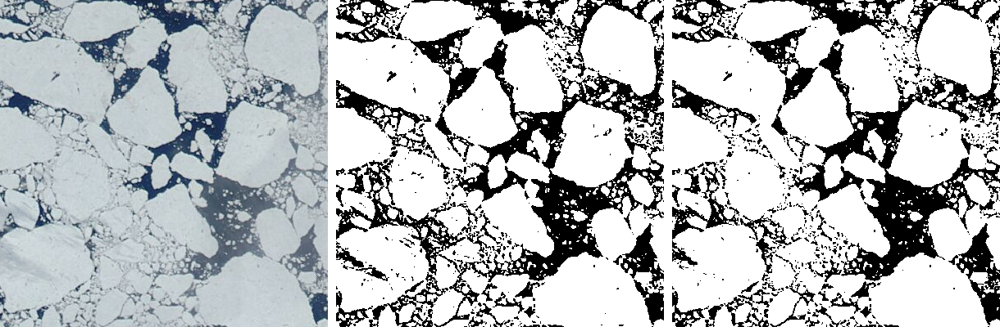

In [30]:
case = first(filter(c -> c.case_number == 63, dataset));
tc_img = modis_truecolor(case)
blank = RGBA(0,0,0,0)
gray_img = float64.(Gray.(tc_img))
smoothed = imfilter(gray_img, Kernel.gaussian(40))
imbinary_10km = Gray.((gray_img .- smoothed) .> 0)

smoothed = imfilter(gray_img, Kernel.gaussian(120))
imbinary_30km = Gray.((gray_img .- smoothed) .> 0)
mosaicview(tc_img, imbinary_10km, imbinary_30km, nrow=1, npad=10, fillvalue=blank)

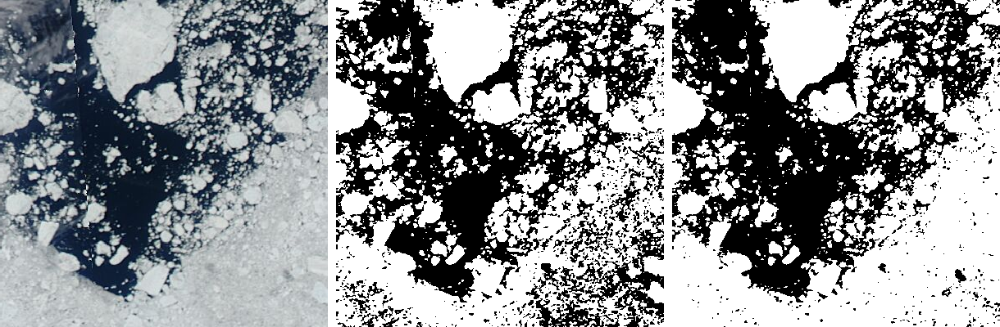

In [3]:
case = first(filter(c -> c.case_number == 14, dataset));
tc_img = modis_truecolor(case)
blank = RGBA(0,0,0,0)
gray_img = float64.(Gray.(tc_img))
smoothed = imfilter(gray_img, Kernel.gaussian(40))
imbinary_10km = Gray.((gray_img .- smoothed) .> 0)

smoothed = imfilter(gray_img, Kernel.gaussian(160))
imbinary_40km = Gray.((gray_img .- smoothed) .> 0)
mosaicview(tc_img, imbinary_10km, imbinary_40km, nrow=1, npad=10, fillvalue=blank)

## k-means binarization
The $k$-means binarization method from Lopez-Acosta 2019 uses the truecolor and falsecolor images, with a preprocessed grayscale image to provide a contrast-adjusted image, subdivided into clusters with $k$-means, then setting a single cluster to 1 based on overlap with a histogram-based ice identification algorithm.

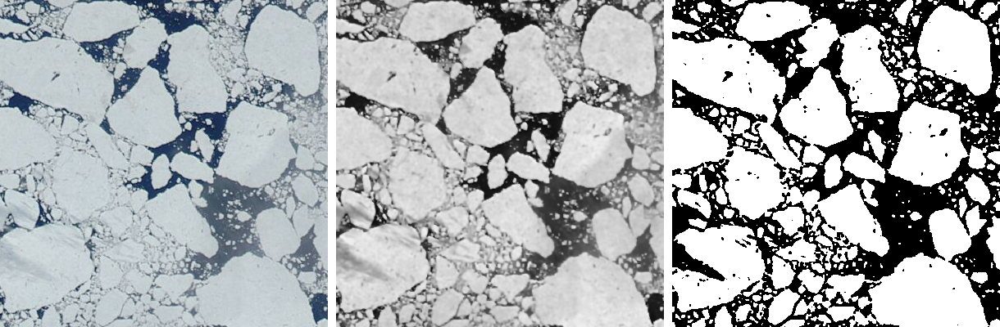

In [4]:
case = first(filter(c -> c.case_number == 63, dataset));
tc_img = modis_truecolor(case)
fc_img = modis_falsecolor(case)
gray_img = Gray.(tc_img)
algo = IceDetectionBrightnessPeaksMODIS721(
        band_7_max=0.2,
        possible_ice_threshold=0.2,
        join_method="union"
    )
blank = RGBA(0,0,0,0)
preproc = nonlinear_diffusion(gray_img, PeronaMalikDiffusion(niters=7))
adjust_histogram!(preproc, 
    ContrastLimitedAdaptiveHistogramEqualization(
        nbins=255, rblocks=2, cblocks=2, clip=2)
    )
preproc .= unsharp_mask(preproc, 10, 0.1)
bin_img = kmeans_binarization(
    preproc, fc_img; 
    k=4,
    cluster_selection_algorithm=algo
)

mosaicview(tc_img, preproc, Gray.(bin_img), nrow=1, npad=10, fillvalue=blank)

This method is highly sensitive to the choices in the preprocessing and sharpening methods. The above binarization was based on varying the "amount" parameter until the result looked good; in other images, much higher "amount" parameters provide better segmentation results.

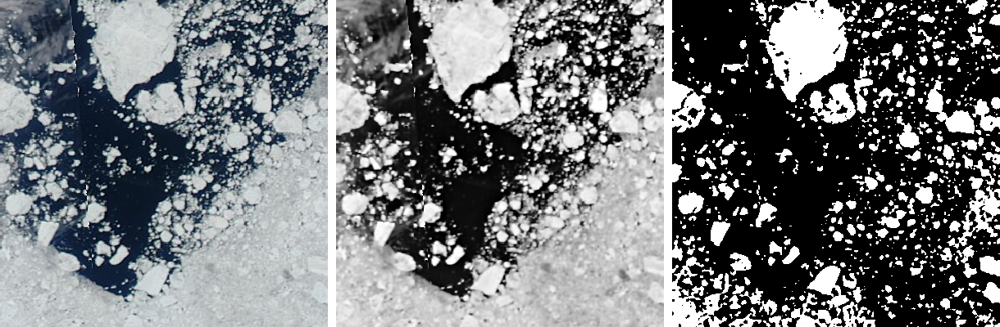

In [5]:
case = first(filter(c -> c.case_number == 14, dataset));
tc_img = modis_truecolor(case)
fc_img = modis_falsecolor(case)
gray_img = Gray.(tc_img)
preproc = nonlinear_diffusion(gray_img, PeronaMalikDiffusion(niters=7))
adjust_histogram!(preproc, 
    ContrastLimitedAdaptiveHistogramEqualization(
        nbins=255, rblocks=2, cblocks=2, clip=1)
    )
preproc .= unsharp_mask(preproc, 10, 0.3)
bin_img = kmeans_binarization(
    preproc, fc_img; 
    k=4,
    cluster_selection_algorithm=algo
    )

mosaicview(tc_img, preproc, Gray.(bin_img), nrow=1, npad=10, fillvalue=blank)

In the pair of images shown here -- Cases 63 Beaufort Sea and 14 Baffin Bay-- we see that both methods do well for the Beaufort Sea image with generally well-defined floe boundaries, while the k-means result does better for the region of floes surrounded by ice melange in Baffin Bay.

In general, this method can work well but can be sensitive to variations in the image.

# Adaptive Threshold Binarization
The JuliaImages ImageBinarization library contains an implementation of image-integral based adaptive threshold algorithm. Similar to the Gaussian kernel method, the image is compared to a locally-computed value; in this case, the mean within a moving window. The size of features which can be detected depends on the size of the window. For comparison with the Gaussian method, where the length scale was set as one standard deviation of the Gaussian filter, we look at the approximate comparison of 2x the Gaussian length scale.

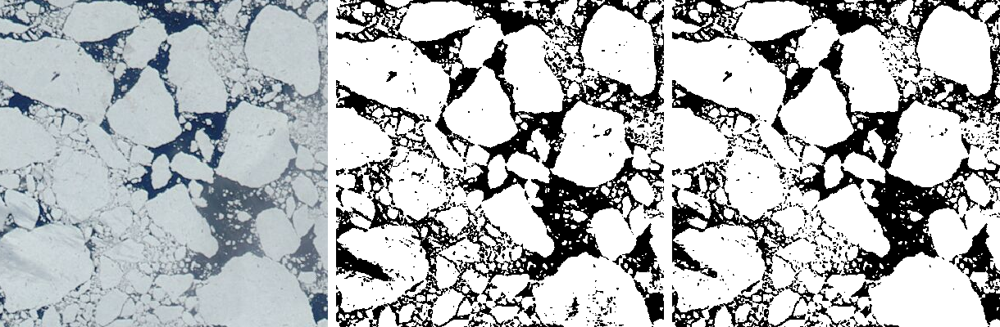

In [6]:
case = first(filter(c -> c.case_number == 63, dataset));
tc_img = modis_truecolor(case)
blank = RGBA(0,0,0,0)
gray_img = float64.(Gray.(tc_img))
imbinary_80px = binarize(gray_img, AdaptiveThreshold(; window_size=80, percentage=0))
imbinary_240px = binarize(gray_img, AdaptiveThreshold(; window_size=240, percentage=0))
mosaicview(tc_img, imbinary_80px, imbinary_240px, nrow=1, npad=10, fillvalue=blank)

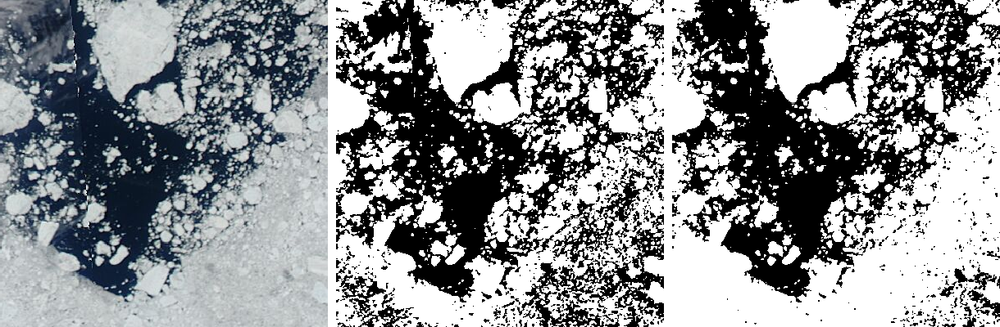

In [7]:
case = first(filter(c -> c.case_number == 14, dataset));
tc_img = modis_truecolor(case)
blank = RGBA(0,0,0,0)
gray_img = float64.(Gray.(tc_img))
imbinary_80px = binarize(gray_img, AdaptiveThreshold(; window_size=80, percentage=0))
imbinary_240px = binarize(gray_img, AdaptiveThreshold(; window_size=240, percentage=0))
mosaicview(tc_img, imbinary_80px, imbinary_240px, nrow=1, npad=10, fillvalue=blank)

The adaptive threshold method and Gaussian methods produce similar results; they both tend to produce a "halo" effect around the transition from open water surrounding floes to floes within brash or thin ice.

# Other methods
* Otsu
* PolySegment
* Intermodes
* MinimumIntermodes

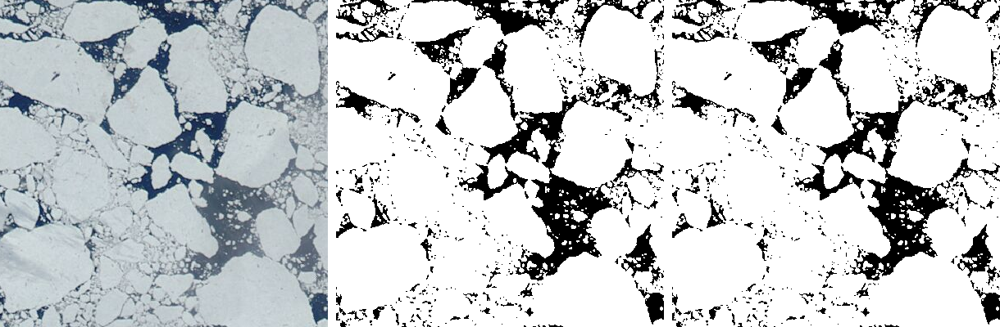

In [8]:
case = first(filter(c -> c.case_number == 63, dataset));
tc_img = modis_truecolor(case)
blank = RGBA(0,0,0,0)
gray_img = float64.(Gray.(tc_img))
mosaicview(tc_img, binarize(gray_img, Otsu()), binarize(gray_img, Polysegment()), nrow=1, fillvalue=blank, npad=10)


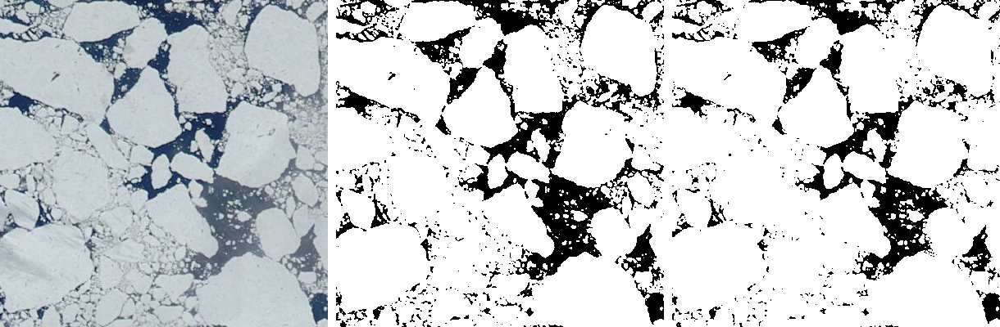

In [9]:
mosaicview(tc_img, binarize(gray_img, Intermodes()), binarize(gray_img, MinimumIntermodes()), nrow=1, fillvalue=blank, npad=10)


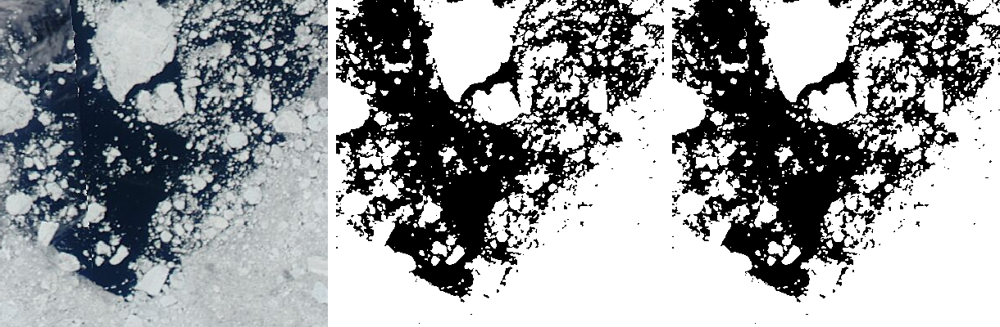

In [10]:
case = first(filter(c -> c.case_number == 14, dataset));
tc_img = modis_truecolor(case)
blank = RGBA(0,0,0,0)
gray_img = float64.(Gray.(tc_img))
mosaicview(tc_img, binarize(gray_img, Otsu()), binarize(gray_img, Polysegment()), nrow=1, fillvalue=blank, npad=10)


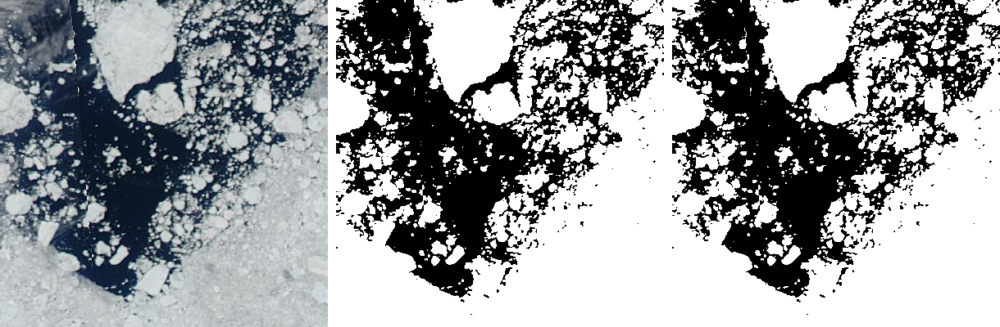

In [11]:
mosaicview(tc_img, binarize(gray_img, Intermodes()), binarize(gray_img, MinimumIntermodes()), nrow=1, fillvalue=blank, npad=10)

Two stage binarization, potentially: find ice, then divide the ice into bright and dark categories. Also, check if  any boundaries within the ice section.